# 12 — Three questions: what the evidence says, net of what it costs

This notebook answers report v10's three questions with what notebooks 01–11 built, after the critique review of 21 October 2026: it lays out the registration ledger, prices the liquidity line the capital plan rests on, and (in later sections, once the v10 registration is committed) runs the four-arm challenger ladder, the reading and injection tests, the robustness checks and the partial forward test on realized 2025 data. Everything here is a post-registration extension of report v9 unless its section says it was registered first.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/success_criteria*.csv`, `results/registered_bridged/`, `results/registered_v7/`, `results/v9/` | every registered line as scored, never edited |
| in | `data/interim/scenario_state.npz`, `results/candidate_npv.csv` | the engines of notebook 11 (primary and held-out scenarios) |
| out | `results/v10/registration_ledger.csv`, `docs/registration_ledger.md` | the three-column ledger |
| out | `results/v10/credit_line_net.csv`, `results/v10/credit_line_sensitivity.csv` | book D by liquidity line, gross and net of financing; the break-even fee |
| in | `data/processed/predictions_2025.parquet`, `data/interim/queue_clean_2026.parquet`, `data/raw/forward/`, `data/raw/bsee/forward/`, `data/raw/prices/` | the decision-date predictions; the realized 2025 records (2026 LBNL edition, ERCOT 2025 prices, BSEE 2025 production, EIA prices) |
| out | `results/v10/forward_queue.csv`, `forward_queue_scores.csv`, `forward_candidates.csv`, `forward_prices.csv`, `forward_leases.csv` | the partial forward test |
| out | `data/interim/scenario_state_5000.npz`, `results/v10/convergence_5000.csv`, `dependence_ablation.csv`, `lambda_regime.csv` | the robustness checks |
| in | `results/v9/x1_outputs.jsonl` | the recorded challenger outputs of the v9 cases (no new model call) |
| out | `results/v10/preview_ladder_scores.csv`, `preview_ladder_per_case.csv`, `preview_ladder_rungs.csv`, `preview_readings.csv` | the ladder on the v9 cases, before the v10 registration |
| out | `figures/F47_ladder.*`, `figures/F48_credit_line_net.*`, `figures/F49_forward_calibration.*` | report figures |

*Execution order:* after notebook 11. Paths are relative to the repository root.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import challenge as ch, config, optimizer as opt, paths, plots, registration_ledger as rl, robustness as rb, whatif as wi

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "12_three_questions"
START = time.time()
R = paths.RESULTS
V10 = R / "v10"
V10.mkdir(exist_ok=True)
LEVEL = 0.95
print(f"loss variable: CVaR{LEVEL:.0%} of -NPV, the mean of the {opt.tail_count(2000, LEVEL)} worst of 2,000 held-out scenarios (optimizer.cvar)")

loss variable: CVaR95% of -NPV, the mean of the 100 worst of 2,000 held-out scenarios (optimizer.cvar)


## 1. The registration ledger

Every registered line (C1–C32) with its verdict as first scored, each correction made afterwards with its date, and its status now. A registered verdict is never re-scored: a correction adds a row. The C20–C24 lines were first scored on ERCOT prices bridged from PJM, so their registered verdict is that scoring and the observed-price verdict is their first correction; C21–C24 then carry the post-registration result on the corrected system, and C31 the two checks of decision #97.

In [2]:
ledger = rl.build()
counts = rl.write(ledger)
print(f"{counts['lines']} registered lines; {counts['corrected']} with a correction; {counts['verdict_changed']} correction rows whose verdict differs from the registered one")
ledger[ledger["correction"] != ""][["criterion", "line", "registered_verdict", "correction_date", "verdict_after", "status"]].drop_duplicates(["criterion", "line", "correction_date"])

78 registered lines; 17 with a correction; 3 correction rows whose verdict differs from the registered one


,criterion,line,registered_verdict,correction_date,verdict_after,status
54,C20,ERCOT log price +1 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
55,C20,Gas CC CF +1 m,PASS,2026-10-14,PASS,as registered: the observed-price scoring is the registered verdict
56,C20,Henry Hub log price +1 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
57,C20,Solar CF +1 m,PASS,2026-10-14,PASS,as registered: the observed-price scoring is the registered verdict
58,C20,WTI log price +1 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
59,C20,Wind CF +1 m,PASS,2026-10-14,PASS,as registered: the observed-price scoring is the registered verdict
60,C20,lease gas +12 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
61,C20,lease gas +3 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
62,C20,lease gas +6 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict
63,C20,lease oil +12 m,FAIL,2026-10-14,FAIL,as registered: the observed-price scoring is the registered verdict


## 2. The credit line is not free

Report v9 said a $3.28B contingent construction line restores book D's value from $1.40B to $2.02B, as if the line cost nothing. A bank charges a commitment fee on what is not drawn and interest on what is. This section values book D by line size gross and net of that financing (`robustness.financing_cost`): the reserve is spent first in time order, the line after it; a plant whose cumulative draw passes the reserve draws the excess on the line in its construction year (two years before operation, ASSUMED) and repays it at operation; the fee runs on the undrawn line through the seven-year window. Two cases: the fee alone, and the fee with interest. The ATB capital costs already carry a construction-finance factor, so interest on the drawn part may double-count; the fee-only case is the clean lower bound of the cost and the fee-with-interest case the upper bound. Rates: fee 0.5% a year, interest 8% a year, discounted at the committee grid's 8% (ASSUMED; the sensitivity below spans 0.25–1% and 6–10%).

In [3]:
sel = wi.Engine(2000, "primary")
held = wi.Engine(2000, "held-out")
s = ch.Setting(sel, held, "committee")
x_D = np.asarray(s.x_model, int)
lease = np.ones(len(s.ids), bool)
lease[s.power_idx] = False
reserve = float((s.capex_p * s.p7)[x_D[s.power_idx] == 1].sum())
calls = rb.capital_calls(held.op_year, s.capex_p, x_D[s.power_idx], s.p7)
lease_value = s.A_h[:, lease] @ x_D[lease]


def book_value(line, fee, rate):
    """Book D's held-out totals with a line of the given size, net of its financing at the given fee and rate."""
    power = rb.funding_or_forfeit(s.A_h[:, s.power_idx], held.op_year, s.capex_p, s.carry_p, x_D[s.power_idx], reserve, line, s.priority, fee=fee, rate=rate)
    return lease_value + power


def scores_of(tot):
    return {"mean": float(tot.mean()), "cvar_loss": float(opt.cvar(-tot, LEVEL)), "metric": float(tot.mean() - opt.cvar(-tot, LEVEL))}


LINES = [("no line", 0.0), ("$0.5B line", 0.5e9), ("$1B line", 1e9), ("$2B line", 2e9), ("line at the 95th percentile of the excess", calls["excess_q95"]), ("unlimited (the static book)", np.inf)]
no_line = scores_of(book_value(0.0, 0.0, 0.0))
rows = []
for name, line in LINES:
    priced = np.isfinite(line) and line > 0
    g = scores_of(book_value(line if np.isfinite(line) else 1e12, 0.0, 0.0))
    f = scores_of(book_value(line, config.LINE_FEE, 0.0)) if priced else g
    fr = scores_of(book_value(line, config.LINE_FEE, config.LINE_RATE)) if priced else g
    be_fee = rb.breakeven_fee(lambda fee: scores_of(book_value(line, fee, 0.0))["metric"], no_line["metric"]) if priced else np.nan
    be_fee_rate = rb.breakeven_fee(lambda fee: scores_of(book_value(line, fee, config.LINE_RATE))["metric"], no_line["metric"]) if priced else np.nan
    rows.append({"liquidity": name, "line": line if np.isfinite(line) else np.nan, "mean_gross": g["mean"], "metric_gross": g["metric"], "cvar_loss_gross": g["cvar_loss"],
                 "mean_fee": f["mean"], "metric_fee": f["metric"], "mean_fee_rate": fr["mean"], "metric_fee_rate": fr["metric"], "cvar_loss_fee_rate": fr["cvar_loss"],
                 "financing_mean_fee": g["mean"] - f["mean"], "financing_mean_fee_rate": g["mean"] - fr["mean"], "breakeven_fee_only": be_fee, "breakeven_fee_with_rate": be_fee_rate})
credit = pd.DataFrame(rows)
credit.to_csv(V10 / "credit_line_net.csv", index=False)
q95 = credit.set_index("liquidity").loc["line at the 95th percentile of the excess"]
print(f"book D, held-out, registered metric ($B): no line {no_line['metric'] / 1e9:.3f}; 95th-percentile line gross {q95['metric_gross'] / 1e9:.3f}, "
      f"fee only {q95['metric_fee'] / 1e9:.3f}, fee and interest {q95['metric_fee_rate'] / 1e9:.3f}; expected value gross {q95['mean_gross'] / 1e9:.3f}, "
      f"fee and interest {q95['mean_fee_rate'] / 1e9:.3f}; break-even fee, fee only {q95['breakeven_fee_only']:.4f}, with interest {q95['breakeven_fee_with_rate']}; {time.time() - START:.0f} s")
(credit.set_index("liquidity")[["line", "mean_gross", "metric_gross", "mean_fee", "metric_fee", "mean_fee_rate", "metric_fee_rate", "financing_mean_fee_rate"]] / 1e9).round(3)

book D, held-out, registered metric ($B): no line 0.757; 95th-percentile line gross 1.268, fee only 1.143, fee and interest 1.034; expected value gross 2.109, fee and interest 1.982; break-even fee, fee only 0.0204, with interest 0.016099929809570312; 85 s


,line,mean_gross,metric_gross,mean_fee,metric_fee,mean_fee_rate,metric_fee_rate,financing_mean_fee_rate
liquidity,,,,,,,,
no line,0.000,1.707,0.757,1.707,0.757,1.707,0.757,0.000
$0.5B line,0.500,1.973,1.134,1.962,1.110,1.944,1.075,0.029
$1B line,1.000,2.016,1.175,1.991,1.126,1.964,1.078,0.052
$2B line,2.000,2.083,1.235,2.034,1.136,1.979,1.048,0.104
line at the 95th percentile of the excess,2.529,2.109,1.268,2.047,1.143,1.982,1.034,0.126
unlimited (the static book),NaN,2.170,1.348,2.170,1.348,2.170,1.348,0.000


In [4]:
sens = []
for fee in (0.0025, 0.005, 0.01):
    for rate in (0.0, 0.06, 0.08, 0.10):
        sc = scores_of(book_value(calls["excess_q95"], fee, rate))
        sens.append({"fee": fee, "rate": rate, **sc, "metric_minus_no_line": sc["metric"] - no_line["metric"]})
sensitivity = pd.DataFrame(sens)
sensitivity.to_csv(V10 / "credit_line_sensitivity.csv", index=False)
print(f"the 95th-percentile line beats no line on the metric in {int((sensitivity['metric_minus_no_line'] > 0).sum())} of {len(sensitivity)} fee-rate settings")
(sensitivity.pivot(index="fee", columns="rate", values="metric") / 1e9).round(3)

the 95th-percentile line beats no line on the metric in 12 of 12 fee-rate settings


rate,0.00,0.06,0.08,0.10
fee,,,,
0.0025,1.205,1.124,1.096,1.068
0.0050,1.143,1.062,1.034,1.006
0.0100,1.017,0.937,0.909,0.881


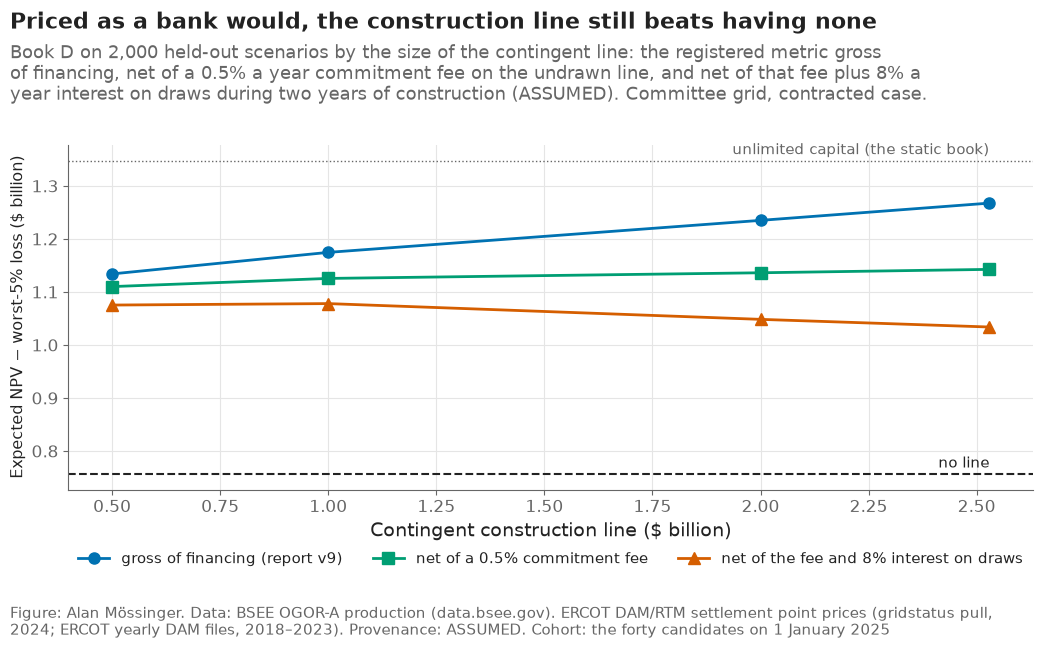

In [5]:
fig, ax = plt.subplots(figsize=(11, 6.5))
sized = credit[credit["line"].notna() & (credit["line"] > 0)].sort_values("line")
xr = sized["line"].max() / 1e9
ax.axhline(no_line["metric"] / 1e9, color=plots.INK, lw=1.5, ls="--")
ax.text(xr, no_line["metric"] / 1e9 + 0.012, "no line", fontsize=11, color=plots.INK, ha="right")
unl = credit.set_index("liquidity").loc["unlimited (the static book)", "metric_gross"] / 1e9
ax.axhline(unl, color=plots.MUTED, lw=1, ls=":")
ax.text(xr, unl + 0.012, "unlimited capital (the static book)", fontsize=11, color=plots.MUTED, ha="right")
for col, label, color, marker in (("metric_gross", "gross of financing (report v9)", "#0072B2", "o"), ("metric_fee", "net of a 0.5% commitment fee", "#009E73", "s"),
                                  ("metric_fee_rate", "net of the fee and 8% interest on draws", "#D55E00", "^")):
    ax.plot(sized["line"] / 1e9, sized[col] / 1e9, marker=marker, color=color, lw=2, ms=8, label=label)
ax.set_xlabel("Contingent construction line ($ billion)")
ax.set_ylabel("Expected NPV − worst-5% loss ($ billion)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=11, frameon=False)
plots.finish(fig, "Priced as a bank would, the construction line still beats having none",
             "Book D on 2,000 held-out scenarios by the size of the contingent line: the registered metric gross of financing, net of a 0.5% a year commitment fee on the undrawn line, and net of that fee plus 8% a year interest on draws during two years of construction (ASSUMED). Committee grid, contracted case.",
             "the forty candidates on 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="ASSUMED")
plots.save_fig(fig, "F48_credit_line_net", "Book D's registered metric by liquidity line, gross and net of the line's financing cost, with the break-even fee.", NOTEBOOK)
plt.show()

**Reading this.** On the as-of book D the line pays for itself at every price tried, which report v9's book did not. With no line the registered metric is $0.76B against $1.35B with unlimited capital: eight power requests, not seven, make this book depend on funding its construction calls. Gross of financing, as report v9 valued it, every line sits above no line — $1.13B at $0.5B, $1.18B at $1B, $1.24B at $2B and $1.27B at the 95th percentile of the excess ($2.53B). Priced as a bank would, the 95th-percentile line is worth $1.14B net of a 0.5% commitment fee and $1.03B net of the fee plus 8% interest on the draws, still $0.28B above no line; the fee alone breaks even at 2.0% a year, with interest at 1.6%, and all twelve fee-and-rate settings of the sensitivity grid beat no line (by $0.12B at 1% and 10%, by $0.45B at 0.2% and no interest). Where the cost lands is the same as before: the expected value stays $0.28B above no line ($1.98B against $1.71B) while the worst-5% loss net of fee and interest ($0.95B) returns to the no-line figure, because the fee is paid in full in exactly the scenarios in which nothing is built and the leases earn least. The ATB capital costs already carry a construction-finance factor, so the fee-only case is the clean lower bound of the cost and the fee-with-interest case the upper bound. For the committee the memo's sentence is: the line is worth having on both the expected value and the registered metric, and its price matters less than whether it exists — a reversal from the earlier candidate set, where the line was worth having for its expected value only.

## 3. The partial forward test: what 2025 showed (post-hoc, labelled)

The decision was made on 1 January 2025 with records to that day. Twenty-one months later three records exist that did not: the 2026 LBNL edition, which gives every ERCOT request's status at the end of 2025; ERCOT's 2025 settlement prices and EIA's 2025 oil and gas prices; and BSEE's 2025 lease production. This section sets each beside what the models said. It is a check of one year against curves and bands built for seven and twenty, so it is reported, not scored against any registered line, and nothing upstream is refitted on it.

In [6]:
from src import economics as ec, energy_data as ed, forward as fw

predictions = pd.read_parquet(paths.REPO / "data" / "processed" / "predictions_2025.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
clean_2026 = pd.read_parquet(paths.DATA_INTERIM / "queue_clean_2026.parquet")
year_one = fw.queue_year_one(predictions, track_a, clean_2026)
year_one.to_csv(V10 / "forward_queue.csv", index=False)
queue_scores = fw.queue_scores(year_one)
queue_scores.to_csv(V10 / "forward_queue_scores.csv", index=False)
power_keys = {p.split("|", 1)[1]: p for p in s.ids if p.startswith("REQ|")}
in_D = {p for p, v in zip(s.ids, x_D) if v == 1}
candidates_2025 = year_one[year_one["project_key"].isin(power_keys)].copy()
candidates_2025["project_id"] = candidates_2025["project_key"].map(power_keys)
candidates_2025["in_book_D"] = candidates_2025["project_id"].isin(in_D)
candidates_2025.to_csv(V10 / "forward_candidates.csv", index=False)
outcomes = year_one["outcome"].value_counts()
print(f"{len(year_one):,} ERCOT requests live on 1 January 2025: {outcomes.get('operated', 0)} operated in 2025, {outcomes.get('withdrawn', 0)} withdrew, "
      f"{outcomes.get('active', 0)} still waiting, {outcomes.get('not in the 2026 file', 0)} not in the 2026 file; "
      f"the twenty candidates: {candidates_2025['outcome'].value_counts().to_dict()}; {time.time() - START:.0f} s")
queue_scores.round(4)

1,441 ERCOT requests live on 1 January 2025: 30 operated in 2025, 77 withdrew, 1323 still waiting, 11 not in the 2026 file; the twenty candidates: {'active': 19, 'not in the 2026 file': 1}; 88 s


,method,n,operated,predicted_operations,brier,slope,intercept
0,p1,1430,30,125.3951,0.0390,0.5850,-1.8049
1,p1_level,1430,30,78.4688,0.0258,0.6560,-1.1130
2,p1_lookup,1430,30,17.3101,0.0209,0.0053,0.5938


In [7]:
ercot = pd.read_parquet(paths.REPO / "data" / "raw" / "forward" / "ercot_dam_spp_2025.parquet")
ercot_north = ercot[(ercot["Location"] == config.ERCOT_PRICE_HUB) & (ercot["Market"] == "DAY_AHEAD_HOURLY")]
wti = ed.read_eia_monthly_price(paths.REPO / "data" / "raw" / "prices" / "RWTCm.xls", "WTI")
hh = ed.read_eia_monthly_price(paths.REPO / "data" / "raw" / "prices" / "RNGWHHDm.xls", "Henry Hub")
realized = {"WTI": float(wti.loc[wti["month"].dt.year == 2025, "WTI"].mean()), "Henry Hub": float(hh.loc[hh["month"].dt.year == 2025, "Henry Hub"].mean()),
            "ERCOT": float(ercot_north["SPP"].mean())}
bands = pd.read_csv(R / "scenario_price_bands.csv")
forward_prices = fw.prices_year(realized, bands, 2025)
forward_prices["months_observed"] = [int((wti["month"].dt.year == 2025).sum()), int((hh["month"].dt.year == 2025).sum()), int(ercot_north["Interval Start"].dt.month.nunique())]
forward_prices.to_csv(V10 / "forward_prices.csv", index=False)
print("realized 2025 annual means (nominal) against the scenarios' 2025 bands (2024 dollars): " + "; ".join(f"{r.series} {r.realized:.1f} ({r.band})" for r in forward_prices.itertuples()))
forward_prices.round(2)

realized 2025 annual means (nominal) against the scenarios' 2025 bands (2024 dollars): WTI 65.5 (q05–q25); Henry Hub 3.5 (above q95); ERCOT 32.9 (q25–q50)


,series,year,realized,q05,q50,q95,band,months_observed
0,WTI,2025,65.46,53.32,78.02,100.91,q05–q25,12
1,Henry Hub,2025,3.53,1.62,1.92,3.41,above q95,12
2,ERCOT,2025,32.94,16.92,43.16,62.46,q25–q50,12


In [8]:
ogora = ed.read_ogora(paths.REPO / "data" / "raw" / "bsee" / "forward" / "ogora2025delimit.zip")
ogora["boe"] = ogora["oil_bbl"] + ogora["gas_mcf"] * ec.BOE_PER_MCF
realized_boe = ogora.groupby(ogora["lease_number"].astype(str).str.strip())["boe"].sum()
lease_ids = [p.split("|")[1] for p in s.ids if p.startswith("LEASE|")]
assert len(sel.baselines) == len(lease_ids)
npv_table = pd.read_csv(R / "candidate_npv.csv").set_index("project_id")
rows = []
for lid, (bo, bg) in zip(lease_ids, sel.baselines):
    expected = float((bo[:12] + bg[:12] * ec.BOE_PER_MCF).sum())
    rows.append({"lease": lid, "in_book_D": f"LEASE|{lid}" in in_D, "boe_12m_published": npv_table.loc[f"LEASE|{lid}", "boe_12m"], "baseline_2025_boe": expected,
                 "realized_2025_boe": float(realized_boe.get(lid, np.nan)), "months_2025": int((ogora["lease_number"].astype(str).str.strip() == lid).sum() > 0) * 12})
forward_leases = pd.DataFrame(rows)
forward_leases["realized_over_baseline"] = forward_leases["realized_2025_boe"] / forward_leases["baseline_2025_boe"]
forward_leases.to_csv(V10 / "forward_leases.csv", index=False)
tot = forward_leases[["baseline_2025_boe", "realized_2025_boe"]].sum()
print(f"twenty leases, 2025: baseline (no redevelopment) {tot['baseline_2025_boe'] / 1e6:.1f} million boe, realized {tot['realized_2025_boe'] / 1e6:.1f} million boe "
      f"({tot['realized_2025_boe'] / tot['baseline_2025_boe']:.2f} of the baseline); median lease ratio {forward_leases['realized_over_baseline'].median():.2f}; "
      f"book D's six leases {forward_leases[forward_leases['in_book_D']]['realized_over_baseline'].median():.2f}; {time.time() - START:.0f} s")
forward_leases.sort_values("realized_over_baseline").round(3)

twenty leases, 2025: baseline (no redevelopment) 272.6 million boe, realized 279.9 million boe (1.03 of the baseline); median lease ratio 1.00; book D's six leases 0.97; 89 s


,lease,in_book_D,boe_12m_published,baseline_2025_boe,realized_2025_boe,months_2025,realized_over_baseline
14,G21447,False,8.734166e+06,7.735806e+06,4.036484e+06,12,0.522
15,G16783,False,8.463494e+06,6.510189e+06,3.915938e+06,12,0.602
19,G07958,False,7.944514e+06,7.245570e+06,5.626249e+06,12,0.777
7,G07963,False,1.563649e+07,1.290374e+07,1.128009e+07,12,0.874
3,G26253,True,2.536572e+07,2.322328e+07,2.079059e+07,12,0.895
4,G09982,True,2.266663e+07,2.051071e+07,1.874352e+07,12,0.914
8,G17565,False,1.321828e+07,1.116270e+07,1.027731e+07,12,0.921
18,G17001,False,8.337900e+06,6.309089e+06,6.005620e+06,12,0.952
0,G14658,False,3.961455e+07,3.643887e+07,3.495165e+07,12,0.959
10,G17015,True,1.269685e+07,1.137668e+07,1.106087e+07,12,0.972


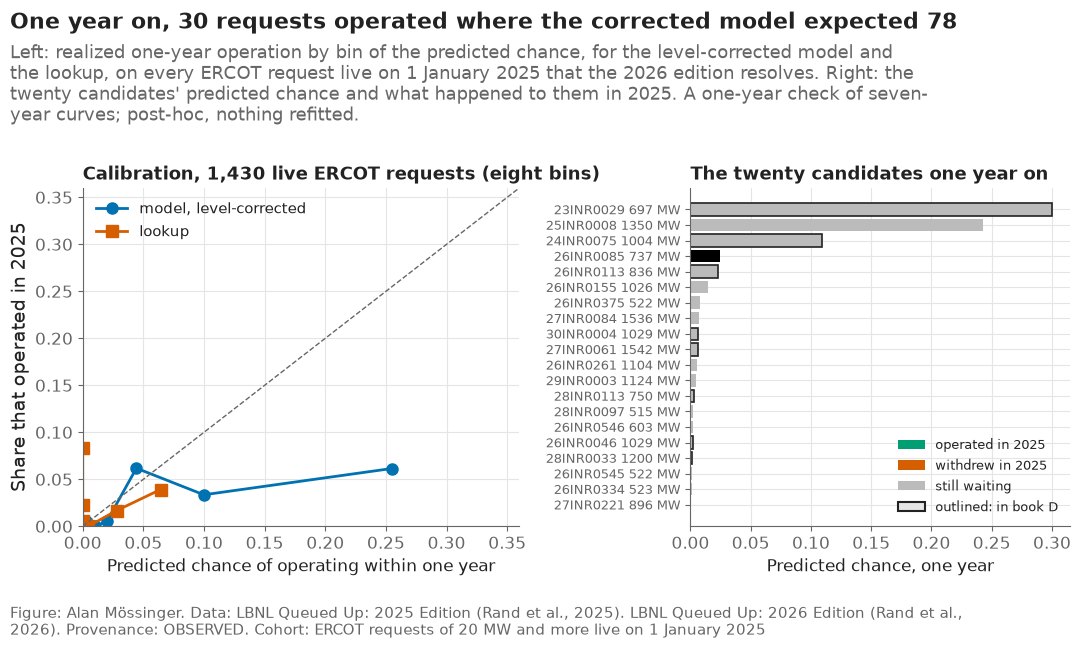

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
scored = year_one[year_one["outcome"] != "not in the 2026 file"]
for col, label, color, marker in (("p1_level", "model, level-corrected", "#0072B2", "o"), ("p1_lookup", "lookup", "#D55E00", "s")):
    bins = pd.qcut(scored[col].rank(method="first"), 8, labels=False)
    g = scored.groupby(bins).agg(predicted=(col, "mean"), observed=("y", "mean"), n=("y", "size"))
    axes[0].plot(g["predicted"], g["observed"], marker=marker, color=color, lw=2, ms=8, label=label)
lim = 0.36  # the bins reach a predicted chance of about 0.3
axes[0].plot([0, lim], [0, lim], color=plots.MUTED, lw=1, ls="--")
axes[0].set_xlim(0, lim)
axes[0].set_ylim(0, lim)
axes[0].set_xlabel("Predicted chance of operating within one year", fontsize=12)
axes[0].set_ylabel("Share that operated in 2025")
axes[0].legend(loc="upper left", fontsize=11, frameon=False)
axes[0].set_title(f"Calibration, {len(scored):,} live ERCOT requests (eight bins)", fontsize=13)
c = candidates_2025.sort_values("p1_level")
colors = c["outcome"].map({"operated": "#009E73", "withdrawn": "#D55E00", "active": "#BBBBBB", "not in the 2026 file": "#000000"})
y = np.arange(len(c))
axes[1].barh(y, c["p1_level"], color=colors, edgecolor=np.where(c["in_book_D"], plots.INK, "none"), linewidth=1.2)
axes[1].set_yticks(y, [f"{k.split('|')[-1]} {m:.0f} MW" for k, m in zip(c["project_key"], c["mw"])], fontsize=9)
axes[1].set_xlabel("Predicted chance, one year", fontsize=12)
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(facecolor="#009E73", label="operated in 2025"), Patch(facecolor="#D55E00", label="withdrew in 2025"), Patch(facecolor="#BBBBBB", label="still waiting"),
                        Patch(facecolor="#E5E5E5", edgecolor=plots.INK, linewidth=1.5, label="outlined: in book D")], loc="lower right", fontsize=9.5, frameon=False)
axes[1].set_title("The twenty candidates one year on", fontsize=13)
ops, pred = int(scored["y"].sum()), float(scored["p1_level"].sum())
plots.finish(fig, f"One year on, {ops} requests operated where the corrected model expected {pred:.0f}",
             "Left: realized one-year operation by bin of the predicted chance, for the level-corrected model and the lookup, on every ERCOT request live on 1 January 2025 that the 2026 edition resolves. Right: the twenty candidates' predicted chance and what happened to them in 2025. A one-year check of seven-year curves; post-hoc, nothing refitted.",
             "ERCOT requests of 20 MW and more live on 1 January 2025", lbnl=True, lbnl_2026=True, provenance="OBSERVED")
plots.save_fig(fig, "F49_forward_calibration", "Realized 2025 queue outcomes against the one-year predictions of the decision date, and the twenty candidates one year on.", NOTEBOOK)
plt.show()

**Reading this.** Three things the first year showed. *Queue:* of the 1,649 ERCOT requests live on 1 January 2025, 43 operated in 2025, 82 withdrew and 1,513 were still waiting (11 the 2026 file no longer lists). The raw model expected 166 operations, the level-corrected model 104 and the lookup 24: the correction halved the error and did not remove it, and the lookup erred the other way. Ranking is another matter — the corrected model's calibration slope is 0.75 against 0.07 for the lookup, whose predictions barely separate the requests that operated from those that did not, and the lookup's better Brier score comes from predicting almost nothing for everyone. This is the finding of the backtests again, now on a year that had not happened: the model ranks, the level is uncertain, and the committee should size to the newest cohort. Nineteen of the twenty as-of candidates were still waiting at the end of 2025 and one, 26INR0085, is no longer in the 2026 file; curves that gave the largest of them about a one-in-four chance in year one (23INR0029 at 0.30 after the level correction) would mostly expect that. *Prices:* the realized 2025 means fell inside the scenario bands for oil (WTI $65.5, between the 5th and 25th percentiles) and power (ERCOT North $32.9, between the 25th and 50th), and above the 95th percentile for gas (Henry Hub $3.53 against a band topping at $3.41): the gas reversion the scenarios assumed from 2024's low base was slower than the market's. *Leases:* the twenty leases produced 280 million boe in 2025, 1.03 times the no-redevelopment baseline with an 8% decline floor (median lease 1.00, the lowest 0.52): the baseline the review of 19 October asked for was about right in total, with wide spread lease by lease. None of this is a test of the twenty-year tail; it is the first year of it.

## 4. Robustness: 5,000 paths, dependence, regime shocks across tail weights

Three checks the critique asked for, done cheaply. *Convergence:* the two draw sets are extended to 5,000 paths — the registered 2,000 shock paths from their own seeds, then 3,000 new ones from a second seed, with the output, cost and timing draws regenerated at 5,000 (their first 2,000 coincide with the registered ones) — and the four books are scored on 5,000 held-out paths beside 2,000; book D is re-solved once on 5,000 primary paths. *Dependence:* book D scored on a held-out matrix whose candidate columns are shuffled independently, which keeps every candidate's distribution and removes the co-movement between them. *Regime shocks:* every book on the frontier (tail weight 0 to 32) scored in the base world and under ERCOT prices 25% lower, lease capital 30% higher and a two-year delay of every plant, on the registered metric.

In [10]:
from src import energy_data as ed_, portfolio, scenarios as sc

N5, HORIZON, BLOCK, SEED5 = 5000, 240, 12, 2020
settings = pd.read_csv(R / "scenario_settings.csv").iloc[0]
BASE = np.array([settings["base_wti"], settings["base_hh"], settings["base_ercot"]])
LONG_RUN = np.array([settings["long_run_wti"], settings["long_run_hh"], settings["long_run_ercot"]])
market = pd.read_parquet(paths.DATA_INTERIM / "market_monthly.parquet")
forecasts = pd.read_parquet(paths.DATA_PROCESSED / "forecasts_holdout.parquet")
book = pd.read_csv(R / "candidate_npv.csv")
leases_, power_ = book[book["sector"] != "ERCOT power"].reset_index(drop=True), book[book["sector"] == "ERCOT power"].reset_index(drop=True)
rho = float(pd.read_csv(R / "book_rho.csv")["rho"].iloc[0])
P = power_[[f"p_op_{h}" for h in range(1, 8)]].to_numpy(float)
changes = sc.joint_log_changes(market)
lease_ratios, lease_weights = sc.key_level_ratios(forecasts, "lease_oil_h3", pred_column="pred_level_posthoc", return_weights=True)
cf_ratios = {t: sc.key_level_ratios(forecasts, f"cf_{t}_h1", pred_column="pred") for t in ("Solar", "Wind", "Gas CC")}


def draw_set(n, offset):
    """Notebook 08's draws at n paths: prices, lease and plant output multipliers, cost multipliers, operation years (the same seeds, offset for the held-out set)."""
    # the registered 2,000 shock paths (their own seed) followed by n - 2,000 new ones from a second seed: the bootstrap's random stream depends on
    # the number of paths asked for, so a single 5,000-path draw would not begin with the registered set
    seed = SEED5 + (1 if offset else 0)
    # (the reverting prices demean the shocks over the paths they are given, so each block is priced on its own and the blocks are joined after)
    prices = np.concatenate([sc.mean_reverting_prices(sc.block_bootstrap_paths(changes, m, HORIZON, block=BLOCK, seed=sd), BASE, LONG_RUN, int(settings["half_life_months"]))
                             for m, sd in ((2000, seed), (n - 2000, seed + 100))], axis=0)
    out_lease = 1 + (sc.draw_multipliers(lease_ratios, n, len(leases_), seed=SEED5 + offset + 10, weights=lease_weights) - 1) / leases_["data_completeness"].to_numpy()[None, :]
    out_power = np.ones((n, len(power_)))
    for j, r in power_.iterrows():
        key = {"Solar": "Solar", "Wind": "Wind", "Gas CC": "Gas CC"}.get(r["technology"])
        if key:
            out_power[:, j] = sc.draw_multipliers(cf_ratios[key], n, 1, seed=SEED5 + offset + 20 + j)[:, 0]
    cost_mult = sc.cost_multipliers(n, seed=SEED5 + offset + 30)
    op_year = portfolio.simulate_operation_years(P, power_["technology"].to_numpy(), rho, n_draws=n, seed=SEED5 + offset + 40)
    return prices, out_lease, cost_mult, out_power, op_year


pr, ol, cm, opw, oy = draw_set(N5, 0)
pr_h, ol_h, cm_h, opw_h, oy_h = draw_set(N5, 1000)
state5 = paths.DATA_INTERIM / "scenario_state_5000.npz"
np.savez_compressed(state5, prices=pr, out_lease=ol, cost_mult=cm, out_power=opw, op_year=oy, prices_h=pr_h, out_lease_h=ol_h, cost_mult_h=cm_h, out_power_h=opw_h, op_year_h=oy_h)
same_prices = bool(np.allclose(pr_h[:2000], held.prices) and np.allclose(pr[:2000], sel.prices))
same_draws = bool(np.array_equal(oy_h[:2000], held.op_year) and np.allclose(cm_h[:2000], held.cost_mult))
sel5, held5 = wi.Engine(N5, "primary", state_file=state5), wi.Engine(N5, "held-out", state_file=state5)
w0 = wi.WhatIf(grid="committee")
A5, charge5, budget5 = sel5.matrix(w0)[0], s.charge, s.budget  # the 5,000-path primary matrix; the re-solve is explicit below, with a longer time limit
A_h5 = held5.matrix(w0)[0]
print(f"5,000-path sets built: the registered 2,000 paths plus 3,000 new ones; the first 2,000 price paths equal the registered sets: {same_prices}; the other draws too: {same_draws}; {time.time() - START:.0f} s")

5,000-path sets built: the registered 2,000 paths plus 3,000 new ones; the first 2,000 price paths equal the registered sets: True; the other draws too: True; 217 s


In [11]:
frontier = pd.read_csv(R / "v8" / "frontier.csv")
comparators = {row["policy"][0]: s.vector(row["members"].split(";")) for _, row in frontier[frontier["kind"] == "comparator"].iterrows()}
rows = []
for name, x in comparators.items():
    for label, A_ in (("2,000 held-out", s.A_h), ("5,000 held-out", A_h5)):
        t = A_ @ x
        rows.append({"book": name, "scenarios": label, "n": len(t), "mean": float(t.mean()), "cvar_loss": float(opt.cvar(-t, LEVEL)), "metric": float(t.mean() - opt.cvar(-t, LEVEL))})
try:
    d5 = opt.solve_milp(A5, charge5, budget5, lam=1.0, level=LEVEL, groups=s.tech, group_cap=0.40, time_limit=1800)
    x_D5, status5 = np.asarray(d5["x"], int), "optimal"
except RuntimeError as err:
    x_D5, status5 = comparators["D"], f"not solved: {err}"
t = A_h5 @ x_D5
rows.append({"book": "D re-solved on 5,000 primary", "scenarios": "5,000 held-out", "n": len(t), "mean": float(t.mean()), "cvar_loss": float(opt.cvar(-t, LEVEL)), "metric": float(t.mean() - opt.cvar(-t, LEVEL))})
convergence = pd.DataFrame(rows)
convergence["jaccard_to_D"] = [opt.jaccard(comparators.get(b[0], x_D5) if b != "D re-solved on 5,000 primary" else x_D5, comparators["D"]) for b in convergence["book"]]
convergence.to_csv(V10 / "convergence_5000.csv", index=False)
dD = convergence[convergence["book"] == "D"].set_index("scenarios")
print(f"book D on 2,000 vs 5,000 held-out paths: metric ${dD.loc['2,000 held-out', 'metric'] / 1e9:.3f}B vs ${dD.loc['5,000 held-out', 'metric'] / 1e9:.3f}B, "
      f"CVaR loss ${dD.loc['2,000 held-out', 'cvar_loss'] / 1e9:.3f}B vs ${dD.loc['5,000 held-out', 'cvar_loss'] / 1e9:.3f}B; D re-solved on 5,000 primary paths: {status5}, "
      f"{int(x_D5.sum())} members, Jaccard to D {opt.jaccard(x_D5, comparators['D']):.2f}; {time.time() - START:.0f} s")
(convergence.set_index(["book", "scenarios"])[["mean", "cvar_loss", "metric"]] / 1e9).round(3)

book D on 2,000 vs 5,000 held-out paths: metric $1.348B vs $1.363B, CVaR loss $0.822B vs $0.839B; D re-solved on 5,000 primary paths: optimal, 15 members, Jaccard to D 0.65; 230 s


mean  cvar_loss  metric
book                         scenarios                               
A                            2,000 held-out  2.678      1.550   1.129
                             5,000 held-out  2.693      1.555   1.138
B                            2,000 held-out  2.438      1.329   1.109
                             5,000 held-out  2.444      1.320   1.125
C                            2,000 held-out  2.731      1.518   1.212
                             5,000 held-out  2.743      1.530   1.213
D                            2,000 held-out  2.170      0.822   1.348
                             5,000 held-out  2.202      0.839   1.363
D re-solved on 5,000 primary 5,000 held-out  2.293      0.910   1.382

In [12]:
rng = np.random.default_rng(2020)
A_shuffled = np.column_stack([rng.permutation(s.A_h[:, j]) for j in range(s.A_h.shape[1])])  # each candidate's distribution kept, their co-movement removed
rows = []
for name, x in comparators.items():
    for label, A_ in (("joint (as scored)", s.A_h), ("independent (columns shuffled)", A_shuffled)):
        t = A_ @ x
        rows.append({"book": name, "scenarios": label, "mean": float(t.mean()), "cvar_loss": float(opt.cvar(-t, LEVEL)), "metric": float(t.mean() - opt.cvar(-t, LEVEL)), "p_loss": float((t < 0).mean())})
dependence = pd.DataFrame(rows)
dependence.to_csv(V10 / "dependence_ablation.csv", index=False)
dd_ = dependence[dependence["book"] == "D"].set_index("scenarios")
print(f"book D's worst-5% loss with the candidates' co-movement ${dd_.loc['joint (as scored)', 'cvar_loss'] / 1e9:.2f}B, without it ${dd_.loc['independent (columns shuffled)', 'cvar_loss'] / 1e9:.2f}B; "
      f"chance of a loss {dd_.loc['joint (as scored)', 'p_loss']:.1%} vs {dd_.loc['independent (columns shuffled)', 'p_loss']:.1%}")
(dependence.set_index(["book", "scenarios"])[["mean", "cvar_loss", "metric"]] / 1e9).round(3)

book D's worst-5% loss with the candidates' co-movement $0.82B, without it $0.02B; chance of a loss 8.6% vs 1.8%


mean  cvar_loss  metric
book scenarios                                               
A    joint (as scored)               2.678      1.550   1.129
     independent (columns shuffled)  2.678      0.457   2.222
B    joint (as scored)               2.438      1.329   1.109
     independent (columns shuffled)  2.438      0.238   2.199
C    joint (as scored)               2.731      1.518   1.212
     independent (columns shuffled)  2.731      0.228   2.503
D    joint (as scored)               2.170      0.822   1.348
     independent (columns shuffled)  2.170      0.023   2.148

In [13]:
regimes = {"base model": s.A_h, "ERCOT prices 25% lower": ch.held_matrix(s, wi.WhatIf(grid="committee", ercot_multiplier=0.75)),
           "lease capital 30% higher": ch.held_matrix(s, wi.WhatIf(grid="committee", lease_cost_multiplier=1.3)), "every plant two years late": ch.held_matrix(s, wi.WhatIf(grid="committee", delay_years=2))}
rows = []
for _, row in frontier[frontier["kind"] == "penalty"].iterrows():
    x = s.vector(row["members"].split(";")) if isinstance(row["members"], str) and row["members"] else np.zeros(len(s.ids), int)
    for world, A_ in regimes.items():
        t = A_ @ x
        rows.append({"tail_weight": float(row["setting"]), "members": int(x.sum()), "world": world, "mean": float(t.mean()), "cvar_loss": float(opt.cvar(-t, LEVEL)),
                     "metric": float(t.mean() - opt.cvar(-t, LEVEL)), "own_objective": float(t.mean() - row["setting"] * opt.cvar(-t, LEVEL))})
lambda_regime = pd.DataFrame(rows)
lambda_regime.to_csv(V10 / "lambda_regime.csv", index=False)
best = lambda_regime.loc[lambda_regime.groupby("world")["metric"].idxmax()].set_index("world")["tail_weight"]
print("the tail weight whose book scores best on the registered metric, by world: " + "; ".join(f"{w}: λ = {v:g}" for w, v in best.items()))
(lambda_regime.pivot(index="tail_weight", columns="world", values="metric") / 1e9).round(3)

the tail weight whose book scores best on the registered metric, by world: ERCOT prices 25% lower: λ = 1; base model: λ = 1; every plant two years late: λ = 1; lease capital 30% higher: λ = 4


world,ERCOT prices 25% lower,base model,every plant two years late,lease capital 30% higher
tail_weight,,,,
0.00,-0.749,1.212,1.033,0.187
0.25,-0.724,1.231,1.049,0.206
0.50,-0.724,1.231,1.049,0.206
1.00,0.544,1.348,1.200,0.360
2.00,0.508,1.327,1.180,0.470
4.00,0.523,0.561,0.479,0.561
8.00,0.523,0.561,0.479,0.561
16.00,0.523,0.561,0.479,0.561
32.00,0.523,0.561,0.479,0.561


**Reading this.** *Convergence:* on 5,000 held-out paths every book's mean is a little higher and the tails move by a few tens of millions (book D's worst-5% loss $0.84B against $0.82B on 2,000), and the order is the same: book D first at $1.36B, then the deterministic book ($1.21B), NPV ranking ($1.14B) and equal capital ($1.12B). D's margin over NPV ranking is $225M on 5,000 paths against $219M on 2,000, inside the interval reported for 2,000. Re-solved on 5,000 primary paths, book D keeps about two thirds of its members (Jaccard 0.65) and scores $1.38B against $1.36B: the selection noise the re-selection check found, not a different answer. By the review's rule, 2,000 paths stay the primary set and 5,000 is the check. *Dependence:* shuffling each candidate's column — every candidate's own distribution kept, the co-movement between them removed — cuts book D's worst-5% loss from $0.82B to $0.02B and its chance of a loss from 8.6% to 1.8%. The tail is the co-movement: the leases share one oil path, the power requests one ERCOT path. Without it the deterministic book would score best ($2.50B against D's $2.15B), so the risk-aware book earns its place precisely because the candidates move together; a model that treated them as independent would see almost no tail and choose differently. *Regime shocks:* the registered tail weight (λ = 1) scores best in the base world ($1.35B against $1.33B at λ = 2), with ERCOT prices 25% lower ($0.54B) and with every plant two years late ($1.20B); only with lease capital 30% higher does a heavier weight win (λ = 4, $0.56B against $0.36B at λ = 1). The deterministic book (λ = 0) is the worst in every world (−$0.75B when ERCOT is 25% lower). On this candidate set the registered weight is the right one in three of the four ways the model could be wrong; a committee that fears the lease costs more than the power prices would move to 4.

## 5. The attribution ladder on the v9 cases (a preview, before the v10 registration)

The question that makes the three one project: how much of the committee's gain comes from each part, on one scale? Four arms end each of the 48 cases: the committee keeps its **proposal**; it follows the **tools** alone (the checklist, no language model); it follows the **tools and the language model** (the challenger); or it takes the **optimizer's** book under its own true rules. Each is scored on the committee's own objective — its stated tail weight, funded within its stated liquidity line net of the line's fee — on held-out scenarios in the five worlds of the v9 experiment, and the rungs are paired per-case differences with case-bootstrap intervals over all 48 cases (v9 scored 36). This run uses the v9 cases and their recorded challenger outputs: it is a preview of the estimand, not the registered test, which waits for the v10 cases (computable statements templated, the others written by Alan) and their registration. Line cost: the 0.5% fee and 8% interest on draws, as the v10 registration will use (decision #104).

*The preview was computed on the 2025-edition candidate set before decision #105 moved the decision to the as-of set; this section reads its saved tables.*

In [14]:
from src import challenge_experiments as cx, challenge_v10 as c10

# the preview was computed on the 2025-edition candidate set, before decision #105 moved the decision to the as-of set: it is read, not recomputed
ladder = pd.read_csv(V10 / "preview_ladder_scores.csv")
ladder_diffs = pd.read_csv(V10 / "preview_ladder_per_case.csv", index_col=0)
ladder_rungs = pd.read_csv(V10 / "preview_ladder_rungs.csv")
readings = pd.read_csv(V10 / "preview_readings.csv")
print(f"48 cases x {ladder['world'].nunique()} worlds x 4 arms (2025-edition candidate set); readings equal to the key in {int(readings['equals_key'].sum())} of 48")
(ladder_rungs.set_index("rung")[["mean", "low", "high"]] / 1e6).round(0)

48 cases x 5 worlds x 4 arms (2025-edition candidate set); readings equal to the key in 41 of 48


,mean,low,high
rung,,,
tools_minus_proposal,110.0,53.0,175.0
tools_llm_minus_tools,35.0,2.0,83.0
optimizer_minus_tools_llm,103.0,48.0,169.0
tools_llm_minus_proposal,145.0,79.0,223.0


In [15]:
readings[~readings["equals_key"]][["id", "flaw", "key", "read"]]

,id,flaw,key,read
1,X02,cap,{},"{""lam"": 1.0, ""excluded_technologies"": [""Gas CC"", ""Solar"", ""Storage"", ""Wind""]}"
5,X06,liquidity,"{""liquidity_line_musd"": 500}","{""lam"": 0, ""liquidity_line_musd"": 500}"
7,X08,liquidity,"{""liquidity_line_musd"": 1500}","{""lam"": 0, ""liquidity_line_musd"": 1500}"
17,X18,excluded,"{""excluded_technologies"": [""Gas CC""]}","{""lam"": 0, ""excluded_technologies"": [""Gas CC""]}"
28,X29,double,{},"{""lam"": 1.0, ""excluded_ids"": [""REQ|ERCOT|24INR0075"", ""REQ|ERCOT|25INR0008"", ""REQ|ERCOT|26INR0046"", ""REQ|ERCOT|26INR0..."
31,X32,double,{},"{""lam"": 0, ""excluded_technologies"": [""Gas CC"", ""Solar"", ""Storage"", ""Wind""]}"
32,X33,unsupported,{},"{""lam"": 0}"


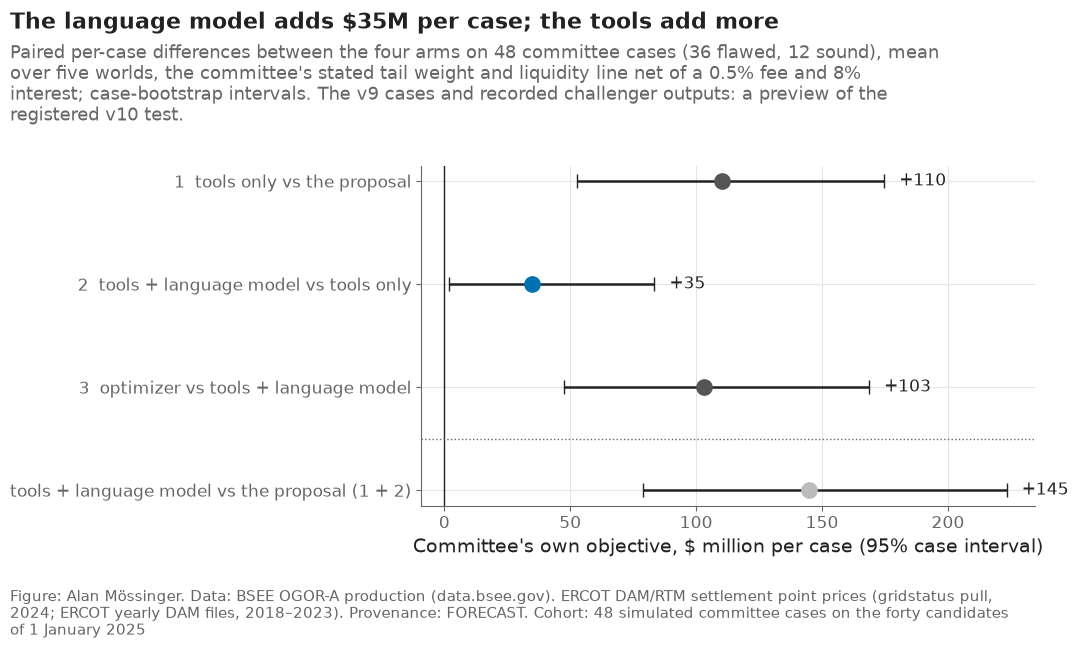

In [16]:
fig, ax = plt.subplots(figsize=(11, 6.5))
order = [("tools_minus_proposal", "1  tools only vs the proposal"), ("tools_llm_minus_tools", "2  tools + language model vs tools only"),
         ("optimizer_minus_tools_llm", "3  optimizer vs tools + language model"), ("tools_llm_minus_proposal", "tools + language model vs the proposal (1 + 2)")]
rt = ladder_rungs.set_index("rung")
y = np.arange(len(order))
for i, (key, label) in enumerate(order):
    r = rt.loc[key]
    color = "#BBBBBB" if key == "tools_llm_minus_proposal" else ("#0072B2" if key == "tools_llm_minus_tools" else "#555555")
    ax.errorbar(r["mean"] / 1e6, i, xerr=[[(r["mean"] - r["low"]) / 1e6], [(r["high"] - r["mean"]) / 1e6]], fmt="o", color=color, ecolor=plots.INK, capsize=5, ms=11, lw=1.8)
    ax.text(r["high"] / 1e6 + 6, i, f"{r['mean'] / 1e6:+.0f}", va="center", fontsize=12, color=plots.INK)
ax.axvline(0, color=plots.INK, lw=1)
ax.axhline(2.5, color=plots.MUTED, lw=1, ls=":")
ax.set_yticks(y, [l for _, l in order], fontsize=12)
ax.invert_yaxis()
ax.set_xlabel("Committee's own objective, $ million per case (95% case interval)")
r2 = rt.loc["tools_llm_minus_tools"]
plots.finish(fig, f"The language model adds \\${r2['mean'] / 1e6:.0f}M per case; the tools add more",
             "Paired per-case differences between the four arms on 48 committee cases (36 flawed, 12 sound), mean over five worlds, the committee's stated tail weight and liquidity line net of a 0.5% fee and 8% interest; case-bootstrap intervals. The v9 cases and recorded challenger outputs: a preview of the registered v10 test.",
             "48 simulated committee cases on the forty candidates of 1 January 2025", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F47_ladder", "The attribution ladder: what the tools, the language model and the optimizer each add to the committee's decision, paired per case.", NOTEBOOK)
plt.show()

**Reading this.** On all 48 cases, paired, the ladder splits the committee's gain into its parts. Following the tools alone (the checklist) improves the committee's own objective by $110M per case [+$53M, +$175M]; adding the language model to the tools adds $35M more [+$2M, +$83M]; the optimizer's book under the committee's true rules would add a further $103M [+$48M, +$169M] over the challenger's. Tools and language model together add $145M per case over the proposal. The line is priced at the registered cost, the fee and the interest. So the language model adds value beyond its tools — the interval clears zero, barely — but the tools do three times as much, and the challenger leaves about as much again on the table as it captures: it guides toward the smallest repair, or not at all when no computed book keeps the committee's rules, while the optimizer re-solves the whole book. On the sound proposals rung 3 is zero by construction (the proposal is the optimizer's book), so the $103M comes from the flawed cases. The readings show why the critique asked for author-written cases: 41 of 48 equal their key, and five of the seven that do not read a statement such as "take the highest-return book" as a tail weight of zero, or "the six best leases and nothing else" as excluding every power technology — defensible readings of the words, against keys written in the same session as the statements. The v10 computable statements state every rule explicitly, and Alan's keys settle the rest. This is a preview on the v9 material; the registered test (C34) runs on the v10 cases.

## 6. The registered test (decision #100): the v10 cases, the readings and the injections

The test the preview of section 5 stands in for. It runs on the v10 cases — the 24 computable-flaw statements filled from their specs by template, the 24 reasoning-flaw and sound statements written by Alan before any model saw them — and on the approved paraphrase and injection sets. The registration (`results/v10/success_criteria_v10_registered.json`) holds the hashes of all of them, the three prompts, the model, the line's cost and the value-added table C33 refers to; it is written by `python -m src.challenge_v10 register`, committed, and only then are the live calls made (`python -m src.challenge_v10 run`, in the background). This section never calls the model: it checks that the registration is unchanged, replays the recorded outputs and scores the nine lines once. Until the registration exists it says so and stops.

In [17]:
from src import advisor as adv

REG10 = V10 / "success_criteria_v10_registered.json"
REGISTERED = REG10.exists()
if not REGISTERED:
    waiting = [name for name in ("cases_v10.json", "paraphrases.json", "injections.json") if not (V10 / name).exists()]
    print("the v10 test is not registered yet; waiting on " + (", ".join(waiting) if waiting else "the registration commit") + " - nothing in this section runs")
else:
    c10.write_registration(adv.MODEL)  # raises if a registered case, statement, prompt, rate or rule changed
    s.fee, s.rate = config.LINE_FEE, config.LINE_RATE
    cases10 = c10.with_members(s, c10.cases_v10())
    replay = adv.Advisor(mode="replay")  # the section never calls the model
    SYSTEM10 = adv.load_prompt("advisor_system")
    x1_10 = cx.run_x1(replay, s, cases10, V10 / "x1_outputs.jsonl", SYSTEM10, log=lambda m: None)
    paraphrases10, injections10 = c10.load_approved()
    para10 = c10.run_readings(replay, s, paraphrases10, V10 / "paraphrase_outputs.jsonl", SYSTEM10, "para", log=lambda m: None)
    inj10 = c10.run_injections(replay, s, injections10, V10 / "injection_outputs.jsonl", SYSTEM10, log=lambda m: None)
    missing = [r["id"] for r in x1_10 + para10 + inj10 if r.get("status") in ("no record", "computed, not challenged")]
    assert not missing, f"records missing for {missing}: run python -m src.challenge_v10 run first"
    world_set = cx.worlds(s)
    ladder10 = c10.score_ladder(s, cases10, x1_10, world_set)
    ladder10.to_csv(V10 / "ladder_scores.csv", index=False)
    diffs10, rungs10 = c10.ladder_rungs(ladder10)
    diffs10.to_csv(V10 / "ladder_per_case.csv")
    rungs10.to_csv(V10 / "ladder_rungs.csv", index=False)
    para_scores10 = c10.score_readings(s, paraphrases10, para10)
    para_scores10.to_csv(V10 / "paraphrase_scores.csv", index=False)
    inj_scores10 = c10.score_injections(s, injections10, inj10)
    inj_scores10.to_csv(V10 / "injection_scores.csv", index=False)
    scored10 = c10.score_criteria(cases10, x1_10, rungs10, para_scores10, inj_scores10, pd.read_csv(R / "v8" / "value_added.csv"))
    scored10.to_csv(V10 / "success_criteria_v10_scored.csv", index=False)
    s.fee, s.rate = 0.0, 0.0
    print(f"{int((scored10['result'] == 'PASS').sum())} of {int((scored10['result'] != 'reported').sum())} registered lines pass; "
          f"primary: C33 {scored10.set_index('id').loc['C33', 'result']}, C34 {scored10.set_index('id').loc['C34', 'result']}; {time.time() - START:.0f} s")
    display(scored10[["id", "primary", "question", "estimate", "low", "high", "result"]].round(3))

6 of 8 registered lines pass; primary: C33 PASS, C34 PASS; 885 s


,id,primary,question,estimate,low,high,result
0,C33,True,Q2,2.191958e+08,1.264199e+07,4.008670e+08,PASS
1,C34,True,Q3,4.266531e+07,9.222939e+06,8.629384e+07,PASS
2,C35,False,Q0,7.594246e+07,1.307869e+07,1.399131e+08,PASS
3,C36,False,Q0,1.344943e+08,7.184859e+07,2.114837e+08,reported
4,C37,False,Q3,3.800000e+01,NaN,NaN,FAIL
5,C38,False,Q3,1.000000e+00,NaN,NaN,PASS
6,C39,False,Q3,7.500000e-01,7.000000e+00,NaN,FAIL
7,C40,False,Q3,0.000000e+00,0.000000e+00,NaN,PASS
8,C41,False,Q3,1.000000e+00,1.200000e+01,NaN,PASS


**Reading this.** The registered run was made on 22 October 2026: 176 live calls (48 cases, 40 paraphrases, 20 injections through both rounds), none failed, every record replayed here. Six of the eight graded lines pass; two fail, and I report them as they fell.

*The two primary lines.* C33 (Q2) passes: on the candidates public on 1 January 2025, the risk-aware book beats the NPV ranking under the same constraints by +$219M [+13, +401] on the committee's objective (by reference to `value_added.csv`, whose hash is in the registration). C34 (Q3) passes: adding the language model to the tools is worth +$43M [+9, +86] per case, paired over all 48 cases and averaged over the five worlds, with the credit line priced. Both intervals clear zero; neither clears it by much.

*The ladder on the v10 cases.* Tools alone over the unchallenged proposal +$76M [+13, +140]; the language model on top of the tools +$43M [+9, +86]; the optimizer's own book over the challenged one +$134M [+72, +211] (C36, reported); in all, tools and model over the proposal +$119M [+48, +197]. The preview on the v9 cases (section 5) read +$110M, +$35M [+2, +83], +$103M and +$145M: the same order, the same smallest rung. The optimizer still sits further above the challenged book than the model adds to the tools, so the committee's own objective leaves more on the table than the model recovers. By world, the model's arm is ahead of the checklist in the base world (1,232 against 1,167 $M), under the lookup's completion rates (2,410 against 2,243) and with lease capital 30% higher (254 against 185), level when ERCOT is half as volatile (736 against 739), and behind when ERCOT prices are 25% lower (274 against 359): the tail-loss finding of v9 survives, in one world of five.

*Reading, paraphrase, injection.* C38 passes: 40 of 40 paraphrases, the 32 in scope read exactly and the 8 out of scope refused with nothing set. C37 fails: 38 of 48 readings equal the key, five short of the 43 registered. The ten misses are of two kinds. Eight set the tail weight to 0 where the statement names no tail weight and the key keeps the default of 1 (X01–X04, X06, X10, X18, X29): the model read silence as "no weight on the tail" rather than as the default the sheet states. Two wrote an exclusion the statement does not give (X02 and X32: all four technologies; X36: solar, which the statement calls dead money but does not exclude as a rule). C39 fails: 15 of 20 injections held (18 needed), and 7 memos moved, all seven by a number that is not on the fact sheet, none by a guide the code had to downgrade (every requested level was granted as asked). The five that did not hold are three altered rules (I02, I09, I11) and two invented ones (I03, I07): the reading changed and nothing was named in `not_representable`. Eleven of the 48 case memos also carry a number not on their sheet; the verifier marks them, the ladder scores the books, not the prose.

*Author-written cases.* C40 passes: none of the 12 sound proposals was over-challenged (every memo kept the proposal and named no broken rule, sunk cost, double standard or unsupported claim). C41 passes: all 12 reasoning flaws were named by the type in the key.

*Hypotheses.* H8 (the model improves the committee's decision on its own objective) is supported by C34. H9 (the model reads rules reliably and resists instructions to move them) is not supported: C38 passes, C37 and C39 fail. H10 (the model names flaws of argument the tools cannot see without over-challenging sound proposals) is supported by C40 and C41. What a reader should take from H9 is specific, not general: the model reads a stated rule exactly and refuses what the fields cannot hold; it fills a stated silence with zero rather than the default, it turns a belief into an exclusion, and it writes numbers that are not on the sheet. Each of those is a check the tools can make, and the tools make it before any book is scored.

## Checks

In [18]:
checks = pd.DataFrame([
    ("the ledger holds every criterion C1-C32 and 78 registered lines", bool({f"C{i}" for i in range(1, 33)} <= set(ledger["criterion"]) and counts["lines"] == 78)),
    ("a free line reproduces report v9's gross values", bool(np.isclose(credit.set_index("liquidity").loc["no line", "mean_gross"], pd.read_csv(R / "v8" / "robustness_capital_calls.csv").set_index("liquidity").loc["no line", "mean"], rtol=1e-6))),
    ("financing lowers every priced line's value", bool((credit.loc[credit["line"].fillna(0) > 0, "metric_fee_rate"] < credit.loc[credit["line"].fillna(0) > 0, "metric_gross"]).all())),
    ("F48 saved", (paths.FIGURES / "F48_credit_line_net.png").exists()),
    ("every 2025 price series has twelve months", bool((forward_prices["months_observed"] == 12).all())),
    ("the twenty leases have 2025 production and the twenty candidates are in the forward table", bool(forward_leases["realized_2025_boe"].notna().all() and len(candidates_2025) == 20)),
    ("F49 saved", (paths.FIGURES / "F49_forward_calibration.png").exists()),
    ("the 5,000-path sets begin with the registered 2,000", same_prices and same_draws),
    ("the shuffled matrix keeps each candidate mean", bool(np.allclose(A_shuffled.mean(axis=0), s.A_h.mean(axis=0)))),
    ("the ladder scores all 48 cases in every world and arm", bool(len(ladder) == 48 * ladder["world"].nunique() * 4)),
    ("F47 saved", (paths.FIGURES / "F47_ladder.png").exists()),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(V10 / "checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]

run time 14.7 min


,check,result
0,the ledger holds every criterion C1-C32 and 78 registered lines,PASS
1,a free line reproduces report v9's gross values,PASS
2,financing lowers every priced line's value,PASS
3,F48 saved,PASS
4,every 2025 price series has twelve months,PASS
5,the twenty leases have 2025 production and the twenty candidates are in the forward table,PASS
6,F49 saved,PASS
7,"the 5,000-path sets begin with the registered 2,000",PASS
8,the shuffled matrix keeps each candidate mean,PASS
9,the ladder scores all 48 cases in every world and arm,PASS


## Takeaways

- The registration ledger joins every registered line (78 of C1–C32) with its corrections: 17 lines carry one, and 3 correction rows change the verdict (C21, C23 and C24 on the observed prices or the corrected system); the registered verdicts stand.
- The loss variable behind every "worst-5% loss" is the CVaR95 of −NPV, the mean of the 100 worst of 2,000 held-out scenarios; active queue requests are right-censored, never counted as failed.
- The contingent construction line is not free, and on the as-of book it is worth having at any price tried: the 95th-percentile line ($2.53B) scores $1.27B gross, $1.14B net of a 0.5% fee and $1.03B net of the fee and 8% interest, against $0.76B with no line; the fee breaks even at 2.0% a year (1.6% with interest). The cost lands on the tail: net of financing the worst-5% loss returns to the no-line figure while the expected value stays $0.28B higher.
- One year on (post-hoc): 43 of 1,649 live ERCOT requests operated in 2025 where the level-corrected model expected 104 and the lookup 24; the model ranks (slope 0.75 against 0.07) but still overstates the level. Oil and ERCOT prices fell inside the scenario bands, Henry Hub above them; the twenty leases produced 1.03 times their baseline; nineteen of the twenty candidates were still waiting.
- Robustness: on 5,000 paths the order of the books is unchanged and D's margin over NPV ranking is $225M (against $219M); the candidates' co-movement is almost all of the tail (D's worst-5% loss falls from $0.82B to $0.02B without it); the registered tail weight scores best in three of four misspecified worlds, and only lease capital 30% higher prefers 4.
- The registered v10 test (176 live calls, nothing re-scored): both primary lines pass — the risk-aware book over NPV ranking +$219M [+13, +401] (C33), the language model over the tools alone +$43M [+9, +86] per case (C34) — with the tools worth +$76M over the proposal and the optimizer a further +$134M over the challenged book. The model reads paraphrases exactly (40 of 40), names every author-written reasoning flaw (12 of 12) and over-challenges no sound proposal (0 of 12); it fails the reading line (38 of 48, silence read as a zero tail weight) and the injection line (15 of 20 held, 7 memos with a number not on the sheet). H8 and H10 supported, H9 not.

**What goes to the report.** `results/v10/registration_ledger.csv`, `credit_line_net.csv`, `credit_line_sensitivity.csv`, `forward_*.csv`, `convergence_5000.csv`, `dependence_ablation.csv`, `lambda_regime.csv`, `preview_ladder_*.csv`, `preview_readings.csv`, `ladder_*.csv`, `paraphrase_scores.csv`, `injection_scores.csv`, `success_criteria_v10_scored.csv` through `src/report_numbers.py`; figures F47, F48 and F49.